# Test des modules serial et pyserial

Elaboration d'un algorythme de lecture série des données de la carte

In [36]:
import serial
import serial.tools.list_ports
import matplotlib.pyplot as plt
import numpy

In [2]:
ports = serial.tools.list_ports.comports()

open_ports = ""
descr = ""

for port, desc, hwid in sorted(ports):
        ##print("{}: {} [{}]".format(port, desc, hwid))
        ##print("{}".format(port))
        descr = "{}".format(desc)
        if (descr == "STM32 STLink - ST-Link VCP Ctrl"):
            open_ports = "{}".format(port)

print("Open ports : ", open_ports)

data_serial = serial.Serial(
    port=open_ports,
    baudrate=115200,
    parity=serial.PARITY_NONE,
    stopbits=serial.STOPBITS_ONE,
    bytesize=serial.EIGHTBITS

)
data_serial.writeTimeout = 0 
data_serial.isOpen()

Open ports :  /dev/ttyACM0


True

In [5]:
data_serial.close()
data_serial.isOpen()

False

In [3]:
print(data_serial)

Serial<id=0x7f3aa9738220, open=True>(port='/dev/ttyACM0', baudrate=115200, bytesize=8, parity='N', stopbits=1, timeout=None, xonxoff=False, rtscts=False, dsrdtr=False)


In [8]:
data_serial.write("Hello World !!!!!".encode("utf-8"))

17

### RX

In [4]:
ID_RX_START = b'0x01'
ID_RX_STOP = b'0x02'
ID_RX_PWM_START = b'0x03'
ID_RX_PWM_STOP = b'0x04'
ID_RX_DUTY_SET = b'0x05'
ID_RX_DIR = b'0x06'
ID_RX_VOLTAGE_SET = b'0x07'

ID_RX_SEND_KP = b'0x08'
ID_RX_SET_KP = b'0x09'

ID_RX_SEND_KP = b'0x0A'
ID_RX_SET_KP = b'0x0B'
ID_RX_SEND_KI = b'0x0C'
ID_RX_SET_KI = b'0x0D'
ID_RX_SEND_KD = b'0x0E'
ID_RX_SET_KD = b'0x0F'

In [5]:
#data_serial.write(b'hello')

def define_trame(msg_id, value, max_size):
    #init
    trame = b''
    byte_length = b''
    
    byte_length = bytes(str(value),'utf-8')
    float_byte_size = len(byte_length)
    index_max_byte = max_size-len(msg_id)-2
    print("index_max_byte :",index_max_byte, " max_size :", max_size)
    trame = msg_id+byte_length[0:index_max_byte]+b';'
    
    #zero filler
    zero_filler = b'0'*(max_size - len(trame)-1)
    trame+= zero_filler
    #EOF Character to end the line, counts as 1 bytes
    trame += bytes('\n', 'utf-8')
    return trame

In [31]:
trame_test = define_trame(ID_RX_START, 0.10102, 16)
print(trame_test, "len :",len(trame_test))
data_serial.write(trame_test)

index_max_byte : 10  max_size : 16
b'0x010.10102;000\n' len : 16


16

In [ ]:
import time

while(1):
    data_serial.write(trame_test)
    time.sleep(0.1)

In [6]:
### FONCTION ENVOI

MSG_MAX_SIZE = 16

def usart_send_start():
    data_serial.write(define_trame(ID_RX_START, 1, MSG_MAX_SIZE))
    
def usart_send_stop():
    data_serial.write(define_trame(ID_RX_STOP, 1, MSG_MAX_SIZE))
    
def usart_send_pwmStart():
    data_serial.write(define_trame(ID_RX_PWM_START, 1, MSG_MAX_SIZE))
    
def usart_send_pwmStop():
    data_serial.write(define_trame(ID_RX_PWM_STOP, 1, MSG_MAX_SIZE))
    
def usart_send_dutyValue(duty_value):
    data_serial.write(define_trame(ID_RX_DUTY_SET, duty_value, MSG_MAX_SIZE))
    
def usart_send_direction(dir_value):
    data_serial.write(define_trame(ID_RX_DIR, dir_value, MSG_MAX_SIZE))
    
def usart_send_voltageValue(voltage_value):
    print("b'' sent : ",data_serial.write(define_trame(ID_RX_VOLTAGE_SET, voltage_value, MSG_MAX_SIZE)))
    
def usart_send_kpAsk(kp_value):
    data_serial.write(define_trame(ID_RX_SET_KP, kp_value, MSG_MAX_SIZE))
    
def usart_send_kpValue():
    data_serial.write(define_trame(ID_RX_SEND_KP, 1, MSG_MAX_SIZE))
    
def usart_send_kiAsk(ki_value):
    data_serial.write(define_trame(ID_RX_SET_KI, ki_value, MSG_MAX_SIZE))
    
def usart_send_kiValue():
    data_serial.write(define_trame(ID_RX_SEND_KI, 1, MSG_MAX_SIZE))
    
def usart_send_kdAsk(kd_value):
    data_serial.write(define_trame(ID_RX_SET_KD, kd_value, MSG_MAX_SIZE))
    
def usart_send_kdValue():
    data_serial.write(define_trame(ID_RX_SEND_KD, 1, MSG_MAX_SIZE))

In [10]:
usart_send_voltageValue(23.0)

index_max_byte : 10  max_size : 16
b'' sent :  16


In [14]:
data_table = []

def read_data(nline):
    it = 0
    data_table = []
    while (it != nline):
        # Read data out of the buffer until a carraige return / new line is found
        data = (data_serial.readline()).decode()
        data = data.split(";")
        print(data)
        
        data_table.append(data)
        it += 1;
    print("out")
    return data_table

In [17]:
#data_serial.reset_input_buffer()
data_test = read_data(200)

['', '', '0', '0', '0x10', '1.128613', '0x11', '021\r030081', '0110x10', '1.108903110.00001', '', '1001', '\r', '', '60\r0', '6001921\r210\r3', '0097174', '0x11', '\r', '0', '1', '\r\r', '04x0\r70.1.\r7.1.\r14', '0\r5.', '', '\r', '0', '\r0x01', '84841', '0x10', '1.096252', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '85851', '0x10', '1.130557', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '86861', '0x10', '1.117396', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '87871', '0x10', '1.123950', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '88881', '0x10', '1.094326', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '89891', '0x10', '1.095619', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '90901', '0x10', '1.121474', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '91911', '0x10', '1.098503', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '92921', '0x10', '1.087558', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '93931', '0x10', '1.101423', '0x11', '0', '

['\r0x01', '185841', '0x10', '1.058246', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '186851', '0x10', '1.106107', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '187861', '0x10', '1.113484', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '188871', '0x10', '1.107490', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '189881', '0x10', '1.101605', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '190891', '0x10', '1.111541', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '191901', '0x10', '1.032756', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '192911', '0x10', '1.111210', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '193921', '0x10', '1.114273', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '194931', '0x10', '1.121297', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '195941', '0x10', '1.113825', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '196951', '0x10', '1.122730', '0x11', '0', '0x12', '0.000000', '\n']
['\r0x01', '197961', '0x10', '1.117513',

In [18]:
print(data_test)

[['', '', '0', '0', '0x10', '1.128613', '0x11', '021\r030081', '0110x10', '1.108903110.00001', '', '1001', '\r', '', '60\r0', '6001921\r210\r3', '0097174', '0x11', '\r', '0', '1', '\r\r', '04x0\r70.1.\r7.1.\r14', '0\r5.', '', '\r', '0', '\r0x01', '84841', '0x10', '1.096252', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '85851', '0x10', '1.130557', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '86861', '0x10', '1.117396', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '87871', '0x10', '1.123950', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '88881', '0x10', '1.094326', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '89891', '0x10', '1.095619', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '90901', '0x10', '1.121474', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '91911', '0x10', '1.098503', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '92921', '0x10', '1.087558', '0x11', '0', '0x12', '0.000000', '\n'], ['\r0x01', '93931', '0x10', '1.101423', '0x1

In [19]:
def compute_data_table(dt):
    ndt = []
    tables = []
    
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            data_line[0] = data_line[0].lstrip('\r') #supprime le \r caractere
            
            for i in range(0, len(data_line)):
                if ((i%2) == 1):
                    data_line[i] = float(data_line[i])
        ndt.append(data_line)
    return ndt


In [20]:
computed_data = (compute_data_table(data_test))
print(computed_data)

[['', '', '0', '0', '0x10', '1.128613', '0x11', '021\r030081', '0110x10', '1.108903110.00001', '', '1001', '\r', '', '60\r0', '6001921\r210\r3', '0097174', '0x11', '\r', '0', '1', '\r\r', '04x0\r70.1.\r7.1.\r14', '0\r5.', '', '\r', '0', '\r0x01', '84841', '0x10', '1.096252', '0x11', '0', '0x12', '0.000000', '\n'], ['0x01', 85851.0, '0x10', 1.130557, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 86861.0, '0x10', 1.117396, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 87871.0, '0x10', 1.12395, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 88881.0, '0x10', 1.094326, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 89891.0, '0x10', 1.095619, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 90901.0, '0x10', 1.121474, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 91911.0, '0x10', 1.098503, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 92921.0, '0x10', 1.087558, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 93931.0, '0x10', 1.101423, '0x11', 0.0, '0x12', 0.0, '\n'], ['0x01', 94941.0, '0x10', 1.105841, '0x11', 0.0, '0x12', 0.0, '\

In [25]:
def time_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (data_line[k] == "0x01"):
                    ndt.append(data_line[k+1]/1000)
                    
    return ndt

def pwm_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            ##print(data_line)
            for k in range(len(data_line)):
                if (data_line[k] == "0x11"):
                    ndt.append(data_line[k+1])
                    
    return ndt

def adc_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (data_line[k] == "0x10"):
                    ndt.append(data_line[k+1])
                    
    return ndt

def speed_getTable(dt):
    ndt = []
    for data_line in dt:
        #print("DATA LINE :", data_line, len(data_line))
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (data_line[k] == "0x12"):
                    ndt.append(data_line[k+1])
                    
    return ndt

In [26]:
time_table = time_getTable(computed_data)
speed_table = speed_getTable(computed_data)
adc_table = adc_getTable(computed_data)
pwm_table = pwm_getTable(computed_data)

In [27]:
print(adc_table)

[1.130557, 1.117396, 1.12395, 1.094326, 1.095619, 1.121474, 1.098503, 1.087558, 1.101423, 1.105841, 1.092731, 1.120922, 1.115669, 1.097397, 1.118678, 1.134169, 1.105076, 1.100341, 1.120655, 1.106667, 1.111445, 1.122412, 1.10434, 1.101347, 1.089502, 1.097974, 1.121132, 1.111635, 1.112408, 1.106912, 1.102634, 1.124222, 1.117355, 1.114244, 1.100451, 1.104724, 1.078047, 1.114067, 1.082933, 1.104607, 1.115971, 1.039269, 1.107557, 1.103164, 1.055255, 1.112848, 1.112557, 1.05313, 1.103808, 1.115196, 1.054936, 1.114515, 1.109609, 1.101372, 1.100798, 1.100004, 1.111916, 1.110646, 1.123473, 1.114914, 1.092182, 1.115427, 1.110837, 1.094312, 1.091278, 1.126162, 1.094748, 1.104861, 1.109166, 1.099838, 1.078884, 1.092878, 1.109561, 1.027068, 1.118077, 1.116951, 1.100817, 1.100485, 1.108027, 1.102815, 1.106925, 1.106123, 1.127273, 1.048357, 1.107262, 1.126818, 1.137851, 1.106727, 1.121181, 1.10563, 1.110857, 1.103311, 1.113482, 1.098965, 1.110183, 1.117162, 1.023955, 1.118015, 1.126141, 1.058246, 1.1

In [28]:
print(time_table)

[85.851, 86.861, 87.871, 88.881, 89.891, 90.901, 91.911, 92.921, 93.931, 94.941, 95.951, 96.961, 97.971, 98.981, 99.991, 101.001, 102.011, 103.021, 104.031, 105.041, 106.051, 107.061, 108.071, 109.081, 110.091, 111.101, 112.111, 113.121, 114.131, 115.141, 116.151, 117.161, 118.171, 119.181, 120.191, 121.201, 122.211, 123.221, 124.231, 125.241, 126.251, 127.261, 128.271, 129.281, 130.291, 131.301, 132.311, 133.321, 134.331, 135.341, 136.351, 137.361, 138.371, 139.381, 140.391, 141.401, 142.411, 143.421, 144.431, 145.441, 146.451, 147.461, 148.471, 149.481, 150.491, 151.501, 152.511, 153.521, 154.531, 155.541, 156.551, 157.561, 158.571, 159.581, 160.591, 161.601, 162.611, 163.621, 164.631, 165.641, 166.651, 167.661, 168.671, 169.681, 170.691, 171.701, 172.711, 173.721, 174.731, 175.741, 176.751, 177.761, 178.771, 179.781, 180.791, 181.801, 182.811, 183.821, 184.831, 185.841, 186.851, 187.861, 188.871, 189.881, 190.891, 191.901, 192.911, 193.921, 194.931, 195.941, 196.951, 197.961, 198.97

In [39]:
time_error_table = []
command_error= 0
for i in range(len(time_table)):
    if (i == 0):
        time_error_table.append(time_table[i]-time_table[i])
        command_error += time_table[i]-time_table[i]
    else:
        time_error_table.append(time_table[i]-time_table[i-1]-1.0)
        command_error += time_table[i]-time_table[i-1]-1.0

command_error /= len(time_error_table)
print(command_error*100)
##plt.step(x= time_table[1:len(time_table)], y= time_error_table[1:len(time_table)])


0.9949748743718685


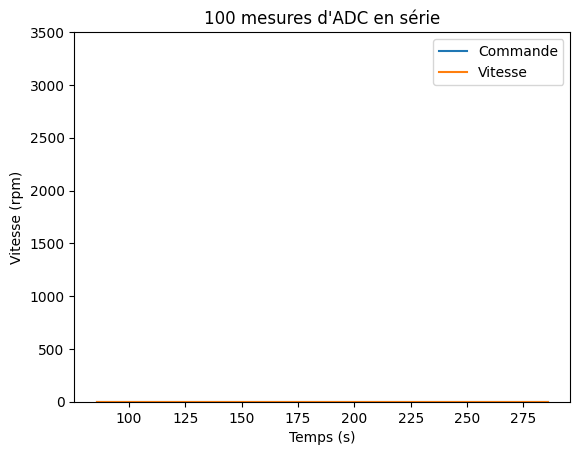

In [34]:
plt.plot(time_table,pwm_table, label = "Commande")
plt.plot(time_table, speed_table, label = "Vitesse")
plt.xlabel("Temps (s)")
plt.ylim([0.0, 3500])
plt.ylabel("Vitesse (rpm)")
plt.title("100 mesures d'ADC en série")
plt.legend()

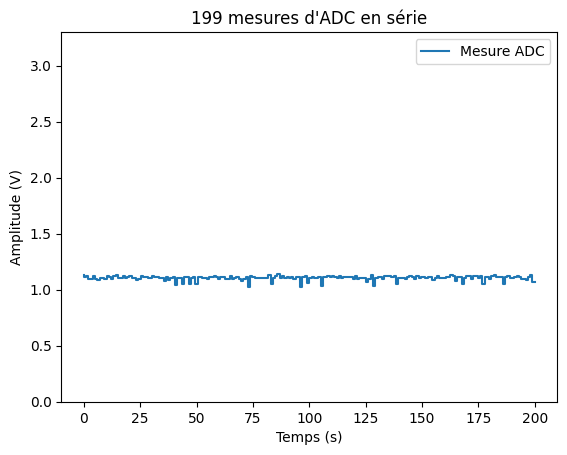

In [37]:
time_table = numpy.array(time_table)-time_table[0]

plt.step(time_table,adc_table, label = "Mesure ADC")#, marker = ".")
plt.xlabel("Temps (s)")
plt.ylim([0.0, 3.3])
plt.ylabel("Amplitude (V)")
plt.title(str(len(time_table))+" mesures d'ADC en série")
plt.legend()